# 01 — Recuperação conjunta: legislação e jurisprudência

Este notebook implementa e avalia a **recuperação conjunta** do LexIA: um único fluxo consulta as duas coleções do mesmo banco PostgreSQL/pgvector e combina os resultados.

| Fonte | Coleção | Unidade buscada | Unidade entregue |
|---|---|---|---|
| Legislação | `lex_clt.chunk_embeddings` (estratégia D, 10.971 chunks) | parágrafo completo | artigo completo (estratégia A) |
| Jurisprudência | `lex_jurisprudencia.embeddings` (303.257 chunks) | janela de 500 tokens | trecho da decisão, com tribunal, processo e data |

Em cada fonte, a busca semântica (BGE-M3) e a busca lexical (full-text search do PostgreSQL) são fundidas por **RRF**. As duas fontes entram na combinação com uma **cota de candidatos** cada, e o cross-encoder **bge-reranker-v2-m3** reordena a lista combinada. Chunks do mesmo artigo ou da mesma decisão são agrupados em uma única unidade.

A busca lexical usa visões materializadas no schema próprio `lex_integracao`; as tabelas de legislação e de jurisprudência não são alteradas. O código está em `src/integracao/recuperacao.py` e `src/integracao/avaliacao_recuperacao.py`.

## 1. Configuração e conexão

In [1]:
from pathlib import Path
import sys, json, time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/integracao').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from worker.evidencia.indices.pgvector_store import load_database_url
from worker.evidencia.recuperador import Recuperador, Configuracao, LEGISLACAO_D, LEGISLACAO_A
from avaliacao import recuperacao as av

RELATORIOS = ROOT / 'dados/relatorios/integracao/recuperacao'
RELATORIOS.mkdir(parents=True, exist_ok=True)
EXECUTAR_AVALIACAO = False   # True recalcula todas as configurações (cerca de 30 min em CPU)
recuperador = Recuperador(load_database_url(ROOT / '.env.pgvector.local'), device='cpu', carregar_reranker=True)
print('Dataset de jurisprudência:', recuperador.dataset_jurisprudencia[:12], '| legislação D:', LEGISLACAO_D[:12], '| A:', LEGISLACAO_A[:12])
COTAS = {'legislacao': 3, 'jurisprudencia': 3}   # posições reservadas por fonte na entrega

Dataset de jurisprudência: cdd4b73c92bc | legislação D: 036e49f3a30a | A: 508abda2246b


## 2. Índice lexical no PostgreSQL

As visões `lex_integracao.lexico_legislacao` e `lex_integracao.lexico_jurisprudencia` guardam o `tsvector` (configuração `portuguese`) de cada chunk, com índice GIN. A consulta usa os lexemas da pergunta combinados com OU e ordena por `ts_rank_cd`. A criação é idempotente.

In [2]:
inicio = time.monotonic()
contagens = recuperador.preparar_lexico()
display(pd.Series(contagens, name='chunks indexados').to_frame())
print(f'Índice lexical pronto em {time.monotonic() - inicio:.0f} s.')

Índice lexical pronto em 0 s.


,chunks indexados
legislacao,10971
jurisprudencia,303257


## 3. Exemplo de busca integrada

Uma pergunta, as duas fontes e o resultado final após fusão e reranking, com **3 posições reservadas para cada fonte**. Para cada unidade entregue, a fonte, a identificação e o início do texto.

In [3]:
pergunta = 'Qual é o adicional devido pelo trabalho noturno urbano?'
entregues, diagnostico = recuperador.buscar(pergunta, Configuracao(entrega_por_fonte=COTAS))
linhas = []
for i, u in enumerate(entregues, 1):
    m = u['metadata']
    ident = (m.get('artigo_ref'), m.get('caminho_relativo', '').split('/')[-1]) if u['fonte'] == 'legislacao' \
        else (m.get('tribunal'), m.get('data_julgamento') or m.get('data_publicacao'))
    linhas.append(dict(posicao=i, fonte=u['fonte'], identificacao=' | '.join(str(x) for x in ident if x),
                       escore_reranker=round(u['escore'], 3), inicio_do_texto=u['texto'][:140].replace('\n', ' ')))
display(pd.DataFrame(linhas))
print(f"{diagnostico['candidatos']} candidatos, {diagnostico['unidades']} unidades, {diagnostico['segundos']:.1f} s.")

20 candidatos, 15 unidades, 10.8 s.


,posicao,fonte,identificacao,escore_reranker,inicio_do_texto
0,1,legislacao,Art. 7º | lei-5889-1973.md,0.833,[leis/1973/lei-5889-1973.md | Art. 7º] ## Art....
1,2,legislacao,Art. 142 | consolidacao-das-leis-do-trabalho-c...,0.630,[codigos/consolidacao-das-leis-do-trabalho-clt...
2,3,legislacao,Art. 73 | consolidacao-das-leis-do-trabalho-cl...,0.589,[codigos/consolidacao-das-leis-do-trabalho-clt...
3,4,jurisprudencia,TRT-10 | 2025-07-02,0.994,pedido. Nada a ser reformado no aspecto. Neg...
4,5,jurisprudencia,TRT-17 | 2021-02-11,0.993,no contracheque. O reclamante reitera seu ped...
5,6,jurisprudencia,TST | 2025-08-14,0.977,do adicional noturno na base de cálculo das ho...


## 4. Gabaritos usados na avaliação

- **Legislação:** perguntas respondíveis dos conjuntos aprovados de desenvolvimento e teste, com norma e artigo esperados. As perguntas sem resposta ficam para os guardrails.
- **Jurisprudência:** perguntas de ajuste com intervalos de suporte anotados. A reserva do teste final do notebook 04 de jurisprudência não é usada.

Todos os documentos de jurisprudência citados no gabarito pertencem ao recorte indexado.

In [4]:
gab_leg = av.gabarito_legislacao(ROOT)
gab_jur = av.gabarito_jurisprudencia(ROOT)
registros = sorted({r for q in gab_jur for r in q['registros']})
presentes = recuperador.conexao.execute(
    'SELECT count(DISTINCT registro_id) FROM lex_jurisprudencia.embeddings WHERE dataset_id=%s AND registro_id = ANY(%s)',
    (recuperador.dataset_jurisprudencia, registros)).fetchone()[0]
assert presentes == len(registros), 'Documento do gabarito fora do índice.'
display(pd.DataFrame([dict(fonte='legislacao', perguntas=len(gab_leg)), dict(fonte='jurisprudencia', perguntas=len(gab_jur),
                      documentos_de_suporte=len(registros), presentes_no_indice=presentes)]))

,fonte,perguntas,documentos_de_suporte,presentes_no_indice
0,legislacao,16,NaN,NaN
1,jurisprudencia,17,16.0,16.0


## 5. Avaliação das configurações

Cada fonte é avaliada sozinha em quatro configurações (semântica, lexical, híbrida por RRF e híbrida com reranker). Nas configurações integradas, as duas fontes são consultadas no mesmo fluxo:

- **integrada (lista única):** legislação e jurisprudência disputam as mesmas posições de uma única lista;
- **integrada com cotas:** cada fonte mantém o próprio ranking e reserva suas posições na entrega (3 artigos e 3 decisões). A posição de cada pergunta é contada dentro da lista da sua fonte.

Métricas: **Hit@k** (a unidade correta está entre as k primeiras), **MRR@10** (inverso da posição da primeira correta) e, na jurisprudência, **cobertura de suporte@k** (fração dos caracteres anotados presentes nos chunks recuperados). Cada configuração é gravada ao terminar em `reports/integracao/recuperacao/resultados_por_pergunta.parquet`; as já concluídas não são recalculadas.

In [5]:
arquivo = RELATORIOS / 'resultados_por_pergunta.parquet'
configs = {
    'semantica':         dict(usar_lexical=False, usar_reranker=False),
    'lexical':           dict(usar_semantica=False, usar_reranker=False),
    'hibrida_rrf':       dict(usar_reranker=False),
    'hibrida_reranker':  dict(),
}
execucoes = []
for nome, opcoes in configs.items():
    for fonte, gab in (('legislacao', gab_leg), ('jurisprudencia', gab_jur)):
        execucoes.append((f'{nome} | {fonte} sozinha', Configuracao(fontes=(fonte,), top_k=10, lexical_modo='ts_rank_cd', cota_por_fonte=25, reranker_max_length=512, **opcoes), gab))
for nome in ('hibrida_rrf', 'hibrida_reranker'):
    execucoes.append((f'{nome} | integrada', Configuracao(top_k=10, lexical_modo='ts_rank_cd', cota_por_fonte=25, reranker_max_length=512, **configs[nome]), gab_leg + gab_jur))
    execucoes.append((f'{nome} | integrada com cotas', Configuracao(top_k=10, entrega_por_fonte=COTAS, lexical_modo='ts_rank_cd', cota_por_fonte=25, reranker_max_length=512, **configs[nome]), gab_leg + gab_jur))
resultados = pd.read_parquet(arquivo) if arquivo.exists() and not EXECUTAR_AVALIACAO else pd.DataFrame()
feitas = set(resultados.configuracao) if len(resultados) else set()
for rotulo, cfg, gab in execucoes:
    if rotulo in feitas:
        continue
    resultados = pd.concat([resultados, av.avaliar(recuperador, gab, cfg, rotulo)], ignore_index=True)
    resultados.to_parquet(arquivo, index=False)
    print('concluído:', rotulo, flush=True)
tabela = av.resumo(resultados)
tabela.to_csv(RELATORIOS / 'resumo_metricas.csv', index=False)
display(tabela)

,configuracao,fonte,hit@1,hit@3,hit@5,hit@10,mrr@10,cobertura@3,cobertura@5,segundos,perguntas
0,hibrida_reranker | integrada,jurisprudencia,0.059,0.118,0.118,0.176,0.088,0.066,0.066,83.565,17
1,hibrida_reranker | integrada,legislacao,0.250,0.500,0.500,0.625,0.377,NaN,NaN,63.755,16
2,hibrida_reranker | integrada com cotas,jurisprudencia,0.059,0.118,0.118,0.176,0.088,0.066,0.066,94.086,17
3,hibrida_reranker | integrada com cotas,legislacao,0.875,1.000,1.000,1.000,0.917,NaN,NaN,82.575,16
4,hibrida_reranker | jurisprudencia sozinha,jurisprudencia,0.059,0.118,0.118,0.176,0.088,0.066,0.066,39.242,17
5,hibrida_reranker | legislacao sozinha,legislacao,0.875,1.000,1.000,1.000,0.917,NaN,NaN,36.366,16
6,hibrida_rrf | integrada,jurisprudencia,0.059,0.059,0.059,0.059,0.059,0.038,0.038,41.995,17
7,hibrida_rrf | integrada,legislacao,0.125,0.562,0.750,0.812,0.339,NaN,NaN,3.791,16
8,hibrida_rrf | integrada com cotas,jurisprudencia,0.059,0.059,0.059,0.235,0.081,0.038,0.038,3.603,17
9,hibrida_rrf | integrada com cotas,legislacao,0.312,0.750,1.000,1.000,0.567,NaN,NaN,3.096,16


## 6. Gráficos

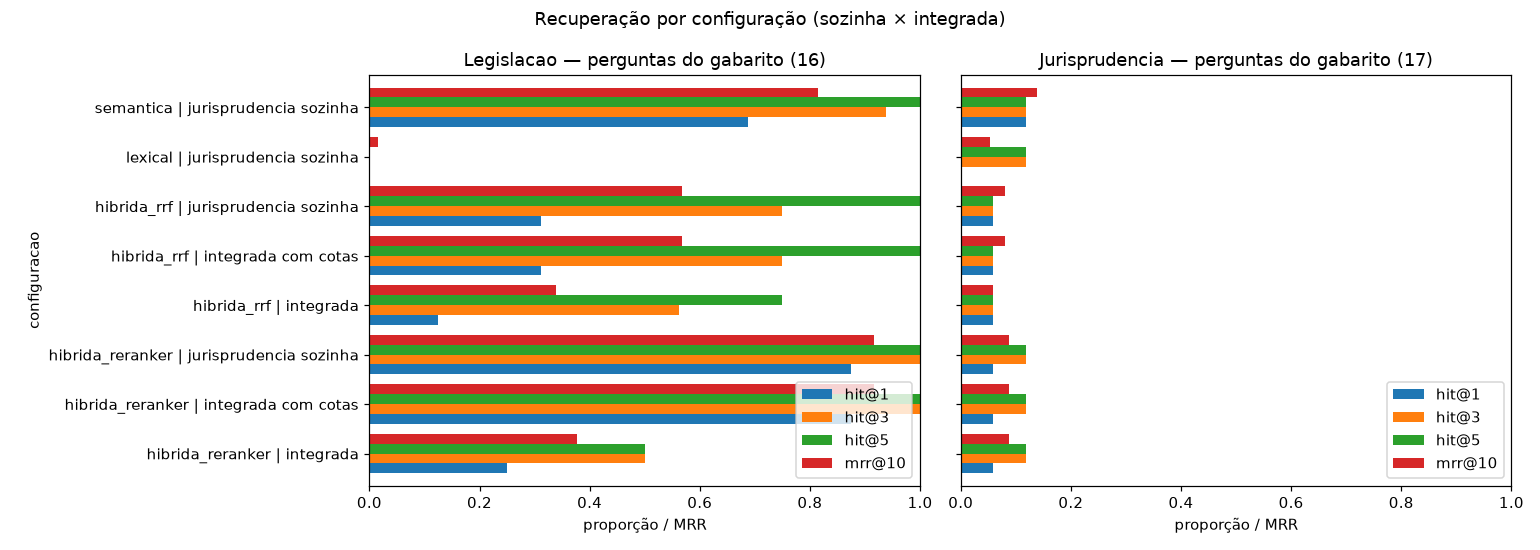

In [6]:
fig, eixos = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for eixo, fonte in zip(eixos, ('legislacao', 'jurisprudencia')):
    t = tabela[tabela.fonte == fonte].set_index('configuracao')[['hit@1', 'hit@3', 'hit@5', 'mrr@10']]
    t.plot.barh(ax=eixo, width=0.8)
    eixo.set_title(f'{fonte.capitalize()} — perguntas do gabarito ({int(tabela[tabela.fonte == fonte].perguntas.iloc[0])})')
    eixo.set_xlim(0, 1)
    eixo.set_xlabel('proporção / MRR')
    eixo.legend(loc='lower right')
fig.suptitle('Recuperação por configuração (sozinha × integrada)')
fig.tight_layout()
fig.savefig(RELATORIOS / 'recuperacao_por_configuracao.png', dpi=130)
plt.show()

## 7. Perguntas em que a unidade correta não aparece no topo

Na configuração integrada com cotas e reranker, as perguntas cuja unidade correta ficou fora das 3 primeiras posições da sua fonte. São os casos a investigar antes da geração.

In [7]:
integrada = resultados[resultados.configuracao == 'hibrida_reranker | integrada com cotas']
falhas = integrada[integrada['hit@3'] == 0][['fonte', 'query_id', 'posicao', 'unidades']]
# Texto só das perguntas de legislação: as de jurisprudência ficam fora do Git (ver .gitignore) e aparecem pelo query_id.
perguntas = {q['query_id']: q['pergunta'] for q in gab_leg}
falhas = falhas.assign(pergunta=falhas.query_id.map(perguntas).str.slice(0, 110))
display(falhas)
print(f'{len(falhas)} de {len(integrada)} perguntas sem a unidade correta entre as 3 primeiras.')

15 de 33 perguntas sem a unidade correta entre as 3 primeiras.


,fonte,query_id,posicao,unidades,pergunta
247,jurisprudencia,juris_001,6.0,35,NaN
248,jurisprudencia,juris_002,NaN,49,NaN
249,jurisprudencia,juris_003,NaN,44,NaN
250,jurisprudencia,juris_004,NaN,44,NaN
251,jurisprudencia,juris_005,NaN,45,NaN
253,jurisprudencia,juris_011,13.0,39,NaN
254,jurisprudencia,juris_012,NaN,39,NaN
255,jurisprudencia,juris_013,NaN,47,NaN
257,jurisprudencia,juris_017,NaN,42,NaN
258,jurisprudencia,juris_019,NaN,45,NaN


## 8. Tempo por pergunta

In [8]:
display(resultados.groupby('configuracao').segundos.describe()[['mean', '50%', 'max']].round(1))

,mean,50%,max
configuracao,,,
hibrida_reranker | integrada,74.0,73.3,100.2
hibrida_reranker | integrada com cotas,88.5,88.8,105.5
hibrida_reranker | jurisprudencia sozinha,39.2,39.0,46.5
hibrida_reranker | legislacao sozinha,36.4,35.3,47.9
hibrida_rrf | integrada,23.5,3.9,634.6
hibrida_rrf | integrada com cotas,3.4,3.2,8.2
hibrida_rrf | jurisprudencia sozinha,3.1,3.0,6.2
hibrida_rrf | legislacao sozinha,0.2,0.2,0.3
lexical | jurisprudencia sozinha,2.0,1.6,3.8


## 9. Custo do reranker: candidatos e tamanho do texto

O reranker é a etapa mais cara na CPU. Duas alavancas reduzem o custo: **quantos candidatos de cada fonte** vão para o reranker (`cota_por_fonte`) e **quantos tokens** ele lê de cada par pergunta–trecho (`reranker_max_length`). A comparação usa a configuração integrada com cotas (3 artigos e 3 decisões), nas mesmas perguntas, e mede qualidade e tempo médio por pergunta. A combinação 25 × 512 é a configuração das seções anteriores.


hit@1             ...       segundos           
fonte       jurisprudencia legislacao  ... jurisprudencia legislacao
cota tokens                            ...                          
10   256             0.059      0.875  ...         20.683     20.970
     512             0.059      0.875  ...        206.489     34.176
15   256             0.059      0.875  ...         26.082     24.827
     512             0.059      0.875  ...         48.452     49.266
25   256             0.059      0.875  ...         39.038     40.999
     512             0.059      0.875  ...         94.086     82.575

[6 rows x 8 columns]

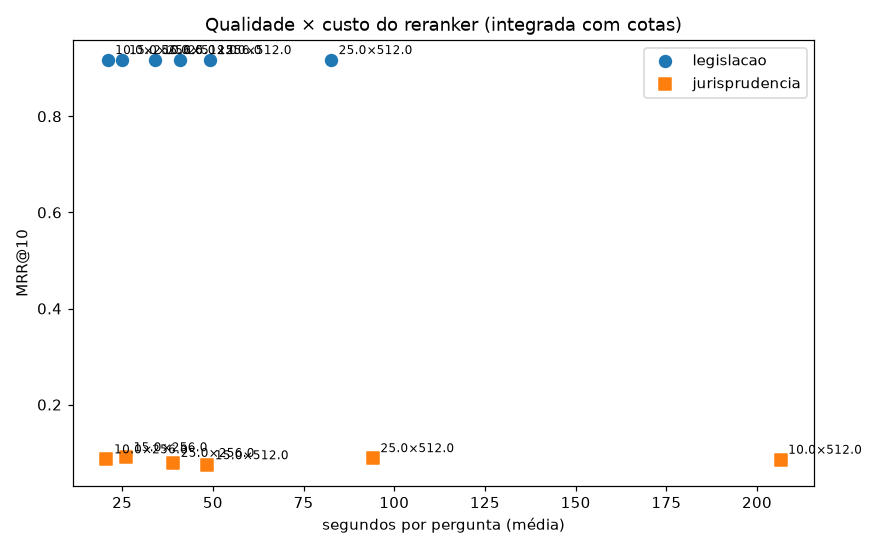

In [9]:
arquivo_custo = RELATORIOS / 'custo_reranker.parquet'
custo = pd.read_parquet(arquivo_custo) if arquivo_custo.exists() else pd.DataFrame()
feitas = set(custo.configuracao) if len(custo) else set()
for cota in (10, 15, 25):
    for tokens in (256, 512):
        rotulo = f'cota {cota} × {tokens} tokens'
        if rotulo in feitas:
            continue
        if (cota, tokens) == (25, 512):
            parte = resultados[resultados.configuracao == 'hibrida_reranker | integrada com cotas'].assign(configuracao=rotulo)
        else:
            cfg = Configuracao(top_k=10, entrega_por_fonte=COTAS, cota_por_fonte=cota, reranker_max_length=tokens, lexical_modo='ts_rank_cd')
            parte = av.avaliar(recuperador, gab_leg + gab_jur, cfg, rotulo)
        custo = pd.concat([custo, parte.assign(cota=cota, tokens=tokens)], ignore_index=True)
        custo.to_parquet(arquivo_custo, index=False)
        print('concluído:', rotulo, flush=True)
tabela_custo = custo.groupby(['cota', 'tokens', 'fonte'])[['hit@1', 'hit@3', 'mrr@10', 'segundos']].mean().round(3).unstack('fonte')
display(tabela_custo)
fig, eixo = plt.subplots(figsize=(8, 5))
for fonte, marcador in (('legislacao', 'o'), ('jurisprudencia', 's')):
    t = custo[custo.fonte == fonte].groupby(['cota', 'tokens']).agg(mrr=('mrr@10', 'mean'), tempo=('segundos', 'mean')).reset_index()
    eixo.scatter(t.tempo, t.mrr, marker=marcador, s=60, label=fonte)
    for _, r in t.iterrows():
        eixo.annotate(f"{r.cota}×{r.tokens}", (r.tempo, r.mrr), textcoords='offset points', xytext=(5, 4), fontsize=8)
eixo.set_xlabel('segundos por pergunta (média)')
eixo.set_ylabel('MRR@10')
eixo.set_title('Qualidade × custo do reranker (integrada com cotas)')
eixo.legend()
fig.tight_layout()
fig.savefig(RELATORIOS / 'custo_reranker.png', dpi=130)
plt.show()

## 10. Ajuste da busca lexical: pesos IDF

A busca lexical sozinha teve Hit@3 = 0 na legislação. A causa foi a ordenação por `ts_rank_cd`, que mede só a densidade dos termos no chunk e não a raridade deles. Com os lexemas da pergunta combinados por OU, termos genéricos como "trabalho", "empregado" e "direito" dominam, e chunks curtos e genéricos sobem para o topo.

A nova ordenação (`lexical_modo='idf'`, agora padrão) soma o peso **IDF** de cada lexema da pergunta presente no chunk, com a fórmula do BM25: `log((N − df + 0,5)/(df + 0,5) + 1)`. Lexemas presentes em mais de 20% dos chunks da fonte são descartados (`lexical_poda`), porque funcionam como stopwords do domínio. Abaixo, a busca lexical sozinha nas duas ordenações e a configuração completa (integrada com cotas) com a nova busca lexical.

In [10]:
COTA_PADRAO, TOKENS_PADRAO = 10, 256   # escolhidos na seção 9; são os padrões de Configuracao
arquivo_lexical = RELATORIOS / 'busca_lexical_modos.parquet'
lexical = pd.read_parquet(arquivo_lexical) if arquivo_lexical.exists() else pd.DataFrame()
feitas = set(lexical.configuracao) if len(lexical) else set()
execucoes = []
for fonte, gab in (('legislacao', gab_leg), ('jurisprudencia', gab_jur)):
    execucoes.append((f'lexical | {fonte} sozinha | idf', gab,
                      Configuracao(fontes=(fonte,), top_k=10, usar_semantica=False, usar_reranker=False, lexical_modo='idf')))
    execucoes.append((f'hibrida_rrf | {fonte} sozinha | idf', gab,
                      Configuracao(fontes=(fonte,), top_k=10, usar_reranker=False, lexical_modo='idf')))
execucoes.append(('hibrida_reranker | integrada com cotas | idf', gab_leg + gab_jur,
                  Configuracao(top_k=10, entrega_por_fonte=COTAS, cota_por_fonte=COTA_PADRAO,
                               reranker_max_length=TOKENS_PADRAO, lexical_modo='idf')))
for rotulo, gab, cfg in execucoes:
    if rotulo in feitas:
        continue
    lexical = pd.concat([lexical, av.avaliar(recuperador, gab, cfg, rotulo)], ignore_index=True)
    lexical.to_parquet(arquivo_lexical, index=False)
    print('concluído:', rotulo, flush=True)
# Referências com a ordenação anterior (ts_rank_cd): seções 5 e 9.
anteriores = resultados[resultados.configuracao.str.match(r'(lexical|hibrida_rrf) \| \w+ sozinha$')].assign(
    configuracao=lambda d: d.configuracao + ' | ts_rank_cd')
referencia = custo[(custo.cota == COTA_PADRAO) & (custo.tokens == TOKENS_PADRAO)].assign(
    configuracao='hibrida_reranker | integrada com cotas | ts_rank_cd')
comparacao = pd.concat([anteriores, referencia, lexical], ignore_index=True)
tabela_lexical = av.resumo(comparacao)[['configuracao', 'fonte', 'hit@1', 'hit@3', 'hit@10', 'mrr@10', 'segundos']]
tabela_lexical.to_csv(RELATORIOS / 'busca_lexical_modos.csv', index=False)
display(tabela_lexical.sort_values(['fonte', 'configuracao']).reset_index(drop=True))

,configuracao,fonte,hit@1,hit@3,hit@10,mrr@10,segundos
0,hibrida_reranker | integrada com cotas | idf,jurisprudencia,0.059,0.176,0.294,0.130,18.451
1,hibrida_reranker | integrada com cotas | ts_ra...,jurisprudencia,0.059,0.118,0.176,0.086,20.683
2,hibrida_rrf | jurisprudencia sozinha | idf,jurisprudencia,0.176,0.235,0.294,0.211,1.345
3,hibrida_rrf | jurisprudencia sozinha | ts_rank_cd,jurisprudencia,0.059,0.059,0.235,0.081,3.118
4,lexical | jurisprudencia sozinha | idf,jurisprudencia,0.176,0.235,0.235,0.196,0.775
5,lexical | jurisprudencia sozinha | ts_rank_cd,jurisprudencia,0.000,0.118,0.235,0.054,1.982
6,hibrida_reranker | integrada com cotas | idf,legislacao,0.875,1.000,1.000,0.927,15.097
7,hibrida_reranker | integrada com cotas | ts_ra...,legislacao,0.875,1.000,1.000,0.917,20.970
8,hibrida_rrf | legislacao sozinha | idf,legislacao,0.688,1.000,1.000,0.823,0.229
9,hibrida_rrf | legislacao sozinha | ts_rank_cd,legislacao,0.312,0.750,1.000,0.567,0.236


## 11. Conclusões

**1. Legislação: a recuperação está resolvida.** Na configuração final (híbrida com IDF + reranker, cotas por fonte), o artigo esperado aparece entre os 3 primeiros em **todas as 16 perguntas** (Hit@3 = 1,00; Hit@1 = 0,875; MRR@10 = 0,93).

**2. A busca lexical era fraca pela ordenação, não pelo índice (seção 10).** Com `ts_rank_cd`, a busca lexical sozinha teve Hit@3 = 0 na legislação. Com pesos IDF e descarte dos termos presentes em mais de 20% dos chunks:
- **na legislação**, a busca lexical sozinha passa a Hit@3 = 0,63 e MRR = 0,55. A híbrida sem reranker sobe de Hit@3 = 0,75 para **1,00** (MRR de 0,57 para 0,82), acima da semântica pura (Hit@3 = 0,94);
- **na jurisprudência**, a híbrida sem reranker sobe de MRR 0,08 para 0,21. Na configuração final, o Hit@10 sobe de 0,18 para 0,29 e o MRR de 0,09 para 0,13.

O modo IDF passa a ser o padrão de `Configuracao`. As seções 5 a 9 mantêm `ts_rank_cd` fixado para reproduzir os números da primeira versão.

**3. Na lista integrada única, a jurisprudência empurra a legislação para baixo; as cotas por fonte resolvem.** Sem cotas, o Hit@3 da legislação cai de 1,00 para 0,50. Com **3 posições reservadas para cada fonte**, cada uma mantém o próprio ranking, e o resultado fica idêntico ao de cada fonte sozinha. A entrega com cotas é a configuração padrão do fluxo integrado.

**4. Custo do reranker (seção 9): 10 candidatos por fonte e 256 tokens.** Essa configuração tem a mesma qualidade de 25 × 512 na legislação e diferença de no máximo uma pergunta na jurisprudência. O tempo cai de cerca de 85 s para **15 a 21 s por pergunta** na CPU, e ela passa a ser o padrão (`cota_por_fonte=10`, `reranker_max_length=256`). O tempo de 206 s medido em 10 × 512 na jurisprudência é uma anomalia de execução (pressão de memória) e não muda a escolha.

**5. Jurisprudência: desempenho ainda baixo e um sinal a investigar.** Na jurisprudência, a híbrida com IDF **sem reranker** (MRR = 0,21) ficou acima da mesma busca **com reranker** (MRR = 0,13). Com 17 perguntas a diferença é de poucas perguntas, mas sugere que o reranker, lendo só 256 tokens de trechos longos de decisões, pode piorar a ordem nessa fonte. A métrica também subestima a qualidade: cada pergunta tem um ou poucos documentos de suporte anotados, num índice de 20.000 decisões com muitas sobre o mesmo tema. Antes de concluir, é preciso julgar a **pertinência** das decisões recuperadas, o que entra na avaliação com juiz.

**Próximos passos:** testar reranker desligado (ou com 512 tokens) só na jurisprudência; avaliação de pertinência com juiz; geração (notebook 03) e avaliação das respostas (notebook 04).